In [162]:
import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

import config

def formatar_numero(valor):
    """Formata no padrão brasileiro: 486.933.121,65"""
    texto = f"{valor:,.2f}"
    return texto.replace(",", "X").replace(".", ",").replace("X", ".")


pd.options.display.float_format = formatar_numero

engine = create_engine(
    URL.create(
        "postgresql+psycopg",
        username=config.DB_USER,
        password=config.DB_PASSWORD,
        host=config.DB_HOST,
        port=config.DB_PORT,
        database=config.DB_NAME,
    )
)


def consultar(sql):
    """Roda uma consulta e devolve um DataFrame."""
    return pd.read_sql(sql, engine)


def grafico_barras(df, categoria, valor, titulo, rotulo_categoria, rotulo_valor):
    """Barras horizontais com título, eixos nomeados e legenda."""
    dados = df.copy()
    dados[valor] = dados[valor].astype(float)
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.barh(dados[categoria].astype(str), dados[valor], label=rotulo_valor)
    ax.invert_yaxis()
    ax.set_title(titulo)
    ax.set_xlabel(rotulo_valor)
    ax.set_ylabel(rotulo_categoria)
    ax.legend()
    ax.ticklabel_format(style="plain", axis="x")
    plt.tight_layout()
    plt.show()

### Pergunta : Viagem de maior duração

,id_viagem,nome_orgao_superior,data_inicio,data_fim,duracao_dias,valor_total
0,0000000000020699856,Ministério da Previdência Social,2025-01-13,2026-01-31,383,"0,00"
1,0000000000020793594,Ministério da Justiça e Segurança Pública,2025-01-02,2026-01-15,378,"120.650,00"
2,0000000000020793492,Ministério da Justiça e Segurança Pública,2025-01-11,2026-01-15,369,"113.382,50"
3,0000000000020774569,Ministério da Educação,2025-02-26,2026-03-02,369,"0,00"
4,0000000000020592696,Ministério da Justiça e Segurança Pública,2025-01-01,2026-01-02,366,"159.044,90"
5,0000000000020685666,Ministério da Justiça e Segurança Pública,2025-01-01,2026-01-02,366,"124.312,50"
6,0000000000020732132,Ministério da Educação,2025-03-31,2026-03-31,365,"0,00"
7,0000000000020589962,Ministério da Educação,2025-02-23,2026-02-23,365,"0,00"
8,0000000000020557147,Ministério da Justiça e Segurança Pública,2025-01-01,2025-12-31,364,"216.729,36"
9,0000000000020649880,Ministério da Justiça e Segurança Pública,2025-01-01,2025-12-31,364,"207.220,14"


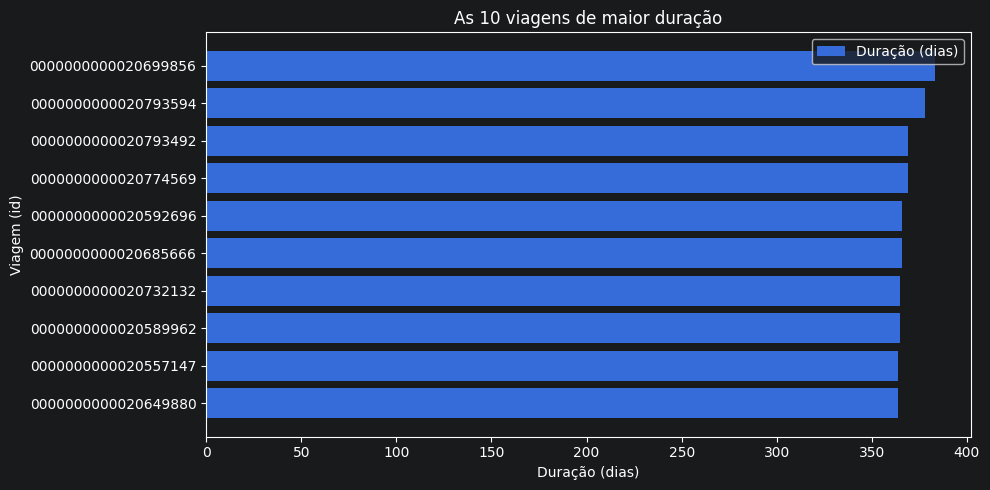

In [163]:
sql_q3 = """
SELECT id_viagem, nome_orgao_superior, data_inicio, data_fim,
       duracao_dias, valor_total
FROM silver_viagem
WHERE duracao_dias IS NOT NULL
ORDER BY duracao_dias DESC, valor_total DESC
LIMIT 10
"""
q3 = consultar(sql_q3)
display(q3)
grafico_barras(q3, "id_viagem", "duracao_dias",
               "As 10 viagens de maior duração",
               "Viagem (id)", "Duração (dias)")

### Pergunta: Meio de transporte mais usado nos trechos

,meio_transporte,qtd_trechos
0,Veículo Oficial,386424
1,Aéreo,232666
2,Rodoviário,64970
3,Veículo Próprio,42846
4,Inválido,26659
5,Fluvial,8429
6,Ferroviário,874
7,Marítimo,481


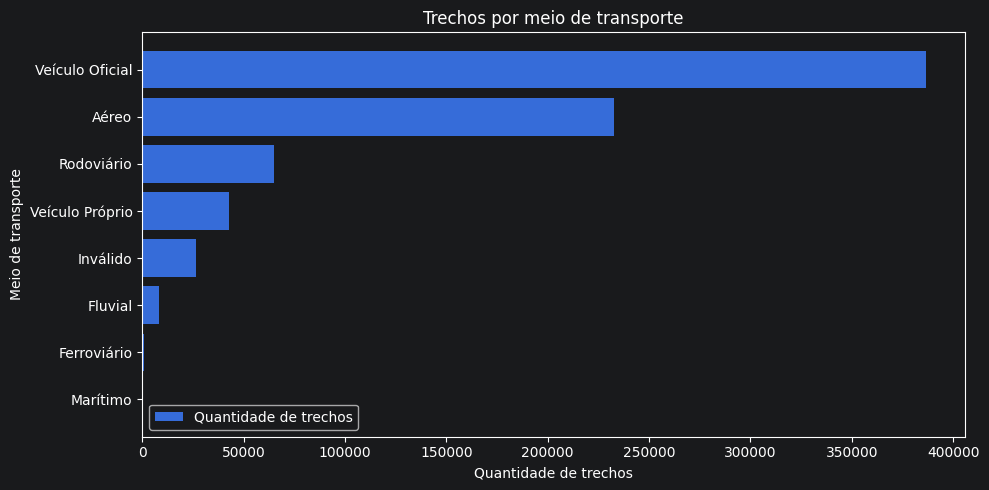

In [164]:
sql_q5 = """
SELECT meio_transporte, COUNT(*) AS qtd_trechos
FROM silver_trecho
WHERE meio_transporte IS NOT NULL
GROUP BY meio_transporte
ORDER BY qtd_trechos DESC
"""
q5 = consultar(sql_q5)
display(q5)
grafico_barras(q5, "meio_transporte", "qtd_trechos",
               "Trechos por meio de transporte",
               "Meio de transporte", "Quantidade de trechos")

### Pergunta: UF de destino mais frequente

,destino_uf,qtd_trechos
0,São Paulo,82722
1,Distrito Federal,79962
2,Minas Gerais,50965
3,Rio de Janeiro,44197
4,Paraná,42603
5,Pará,40044
6,Rio Grande do Sul,38684
7,Mato Grosso do Sul,30516
8,Bahia,28375
9,Pernambuco,28372


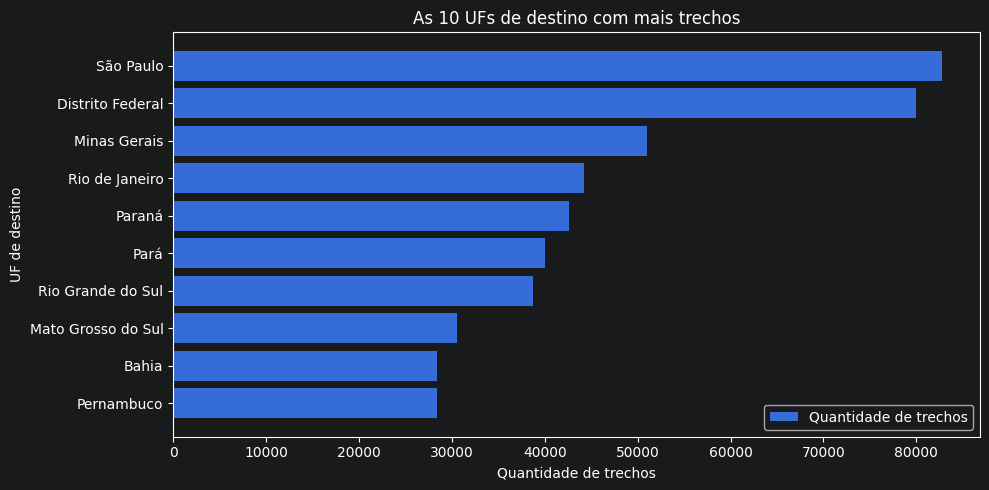

In [165]:
sql_q6 = """
SELECT destino_uf, COUNT(*) AS qtd_trechos
FROM silver_trecho
WHERE destino_uf IS NOT NULL
GROUP BY destino_uf
ORDER BY qtd_trechos DESC
LIMIT 10
"""
q6 = consultar(sql_q6)
display(q6)
grafico_barras(q6, "destino_uf", "qtd_trechos",
               "As 10 UFs de destino com mais trechos",
               "UF de destino", "Quantidade de trechos")

In [166]:
def criar_gold(nome, consulta):
    """Cria a tabela gold_<nome> e a view vw_gold_<nome> com a mesma consulta."""
    with engine.begin() as con:
        con.execute(text(f"DROP VIEW IF EXISTS vw_gold_{nome}"))
        con.execute(text(f"DROP TABLE IF EXISTS gold_{nome}"))
        con.execute(text(f"CREATE TABLE gold_{nome} AS {consulta}"))
        con.execute(text(f"CREATE VIEW vw_gold_{nome} AS {consulta}"))

### Gold 1: custo por órgão superior

In [167]:
gold_orgao_custo = """
SELECT v.nome_orgao_superior,
       COUNT(*) AS qtd_viagens,
       SUM(v.valor_total) AS custo_total,
       ROUND(AVG(v.valor_total), 2) AS custo_medio,
       SUM(COALESCE(p.total_pago, 0)) AS total_pago
FROM silver_viagem v
LEFT JOIN (
    SELECT id_viagem, SUM(valor) AS total_pago
    FROM silver_pagamento
    GROUP BY id_viagem
) p ON p.id_viagem = v.id_viagem
GROUP BY v.nome_orgao_superior
"""

### Gold 2: pagamentos por órgão pagador, tipo e mês

In [168]:
gold_pagamento = """
SELECT p.nome_orgao_pagador,
       p.tipo_pagamento,
       TO_CHAR(v.data_inicio, 'YYYY-MM') AS ano_mes,
       COUNT(p.valor) AS qtd_pagamentos,
       SUM(p.valor) AS valor_total
FROM silver_pagamento p
JOIN silver_viagem v ON v.id_viagem = p.id_viagem
GROUP BY p.nome_orgao_pagador, p.tipo_pagamento,
         TO_CHAR(v.data_inicio, 'YYYY-MM')
"""

### Gold 3: custo por destino

In [169]:
gold_destino = """
SELECT d.destino_uf,
       d.destino_cidade,
       COUNT(*) AS qtd_viagens,
       ROUND(AVG(d.valor_total), 2) AS custo_medio
FROM (
    SELECT DISTINCT t.id_viagem, t.destino_uf, t.destino_cidade, v.valor_total
    FROM silver_trecho t
    JOIN silver_viagem v ON v.id_viagem = t.id_viagem
    WHERE t.destino_cidade IS NOT NULL
) d
GROUP BY d.destino_uf, d.destino_cidade
"""

In [170]:
criar_gold("orgao_custo", gold_orgao_custo)
criar_gold("pagamento", gold_pagamento)
criar_gold("destino", gold_destino)

### Pergunta: 5 órgãos com maior custo total

,nome_orgao_superior,qtd_viagens,custo_total
0,Ministério da Justiça e Segurança Pública,75742,"486.933.121,65"
1,Ministério da Defesa,61912,"156.070.304,49"
2,Ministério da Educação,65295,"111.291.349,34"
3,Ministério do Meio Ambiente e Mudança do Clima,19413,"49.697.710,16"
4,Ministério da Previdência Social,8190,"40.417.309,06"


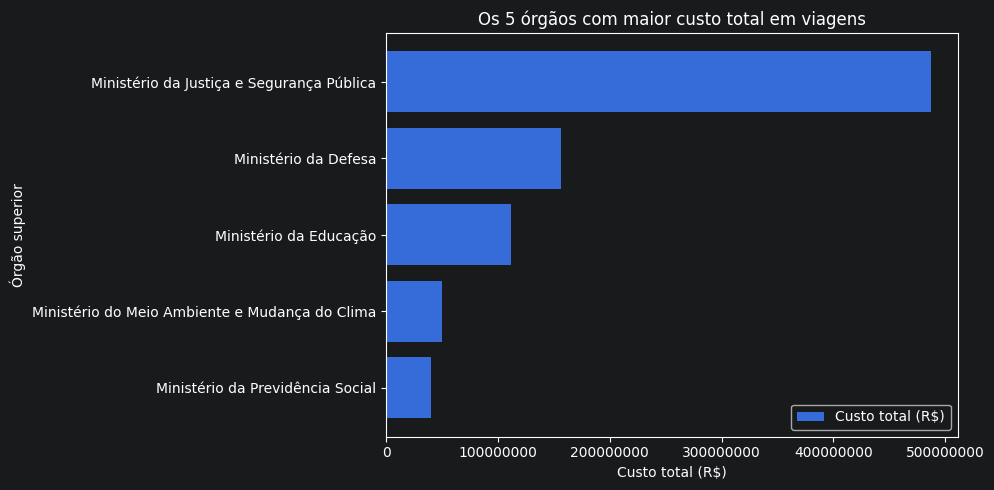

In [171]:
q1 = consultar("""
SELECT nome_orgao_superior, qtd_viagens, custo_total
FROM gold_orgao_custo
ORDER BY custo_total DESC
LIMIT 5
""")
display(q1)

grafico_barras(q1, "nome_orgao_superior", "custo_total",
               "Os 5 órgãos com maior custo total em viagens",
               "Órgão superior", "Custo total (R$)")

### Pergunta: 3 destinos com maior custo médio por viagem

,destino_cidade,destino_uf,qtd_viagens,custo_medio
0,Monte Negro,Rondônia,98,"84.926,03"
1,Novo Santo Antônio,Mato Grosso,24,"79.266,08"
2,Sananduva,Rio Grande do Sul,103,"78.792,23"


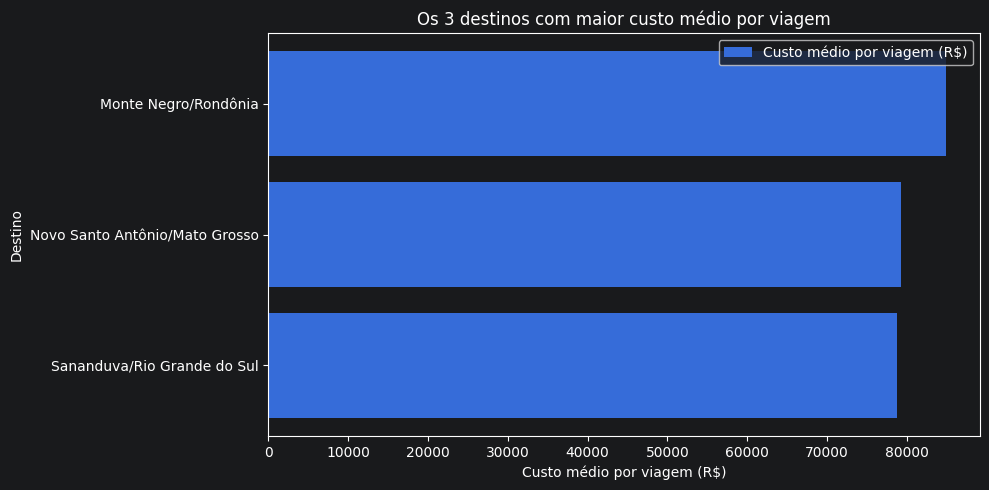

In [172]:
q2 = consultar("""
SELECT destino_cidade, destino_uf, qtd_viagens, custo_medio
FROM gold_destino
WHERE qtd_viagens >= 5
ORDER BY custo_medio DESC
LIMIT 3
""")
display(q2)

q2["destino"] = q2["destino_cidade"] + "/" + q2["destino_uf"].fillna("")
grafico_barras(q2, "destino", "custo_medio",
               "Os 3 destinos com maior custo médio por viagem",
               "Destino", "Custo médio por viagem (R$)")

### Pergunta: tipo de pagamento com maior valor médio

,tipo_pagamento,qtd_pagamentos,valor_medio
0,DIÁRIAS,"401.463,00","2.078,28"
1,PASSAGEM,"188.985,00","1.878,34"
2,Serviço correlato: seguro,"4.894,00","447,51"
3,RESTITUIÇÃO,"11.574,00","245,70"


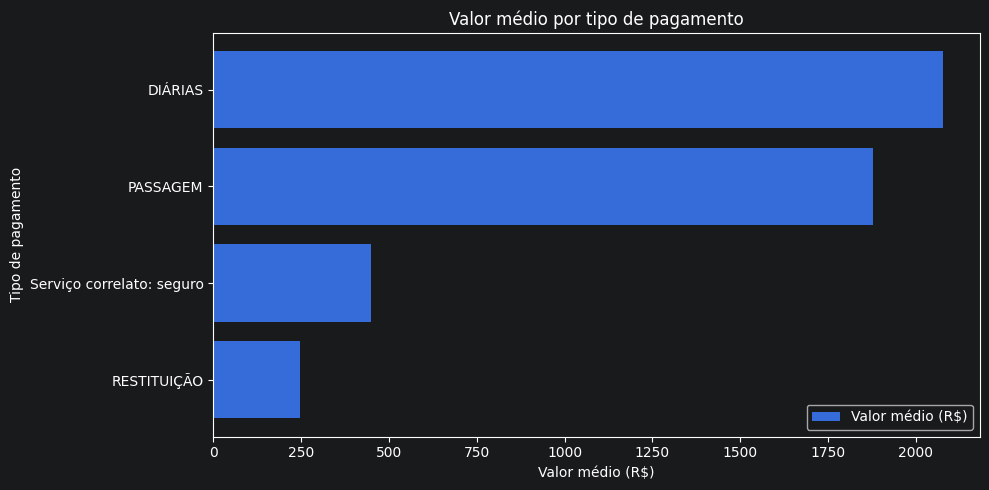

In [173]:
q4 = consultar("""
SELECT tipo_pagamento,
       SUM(qtd_pagamentos) AS qtd_pagamentos,
       ROUND(SUM(valor_total) / NULLIF(SUM(qtd_pagamentos), 0), 2) AS valor_medio
FROM gold_pagamento
GROUP BY tipo_pagamento
ORDER BY valor_medio DESC
""")
display(q4)

grafico_barras(q4, "tipo_pagamento", "valor_medio",
               "Valor médio por tipo de pagamento",
               "Tipo de pagamento", "Valor médio (R$)")

### Pergunta: órgão que pagou mais no total

In [174]:
q7 = consultar("""
SELECT nome_orgao_pagador, SUM(valor_total) AS total_pago
FROM gold_pagamento
WHERE nome_orgao_pagador IS NOT NULL
GROUP BY nome_orgao_pagador
ORDER BY total_pago DESC
LIMIT 5
""")
display(q7)

,nome_orgao_pagador,total_pago
0,Fundo Nacional de Segurança Pública,"278.481.047,89"
1,Sigiloso,"200.484.801,68"
2,Comando da Aeronáutica,"81.769.144,77"
3,Instituto Nacional do Seguro Social,"37.427.601,45"
4,Comando do Exército,"36.872.643,95"
